# Network nonlocality with tripartite entangled sources: companion notebook

**Authors:** Sudip Chakrabarty (S. N. Bose National Centre for Basic Sciences, Kolkata) and Amit Kundu (The Institute of Mathematical Sciences, Chennai)

This notebook reproduces every number, table entry and figure of the manuscript *Network nonlocality with tripartite entangled sources*. It follows the order of the paper:

| Part | Paper | What is computed |
|---|---|---|
| 0 | Fig. 1 | Schematic of the closed and open networks |
| 1 | Sec. II | Pauli matrices, states, the correlation tensor $T_{\mu k\nu}$, Mermin and Svetlichny values |
| 2 | Sec. III A, App. A | Local bounds (Theorem 1, Proposition 3) tested on random hidden-variable models |
| 3 | Sec. III B, App. B | Closed-network value $\mathcal N_c$ (Proposition 1), checked against a direct six-qubit calculation |
| 4 | Sec. III C–D | Theorem 2 and the examples: GHZ, generalized GHZ, $W$, biseparable states, Table III, Figs. 2 and 3 |
| 5 | Sec. IV, App. F | Entanglement swapping through two central nodes (Proposition 2), noise, Fig. 4 |
| 6 | Sec. V, App. D | Open network, the value $2$ for GHZ sources, Theorem 3 |
| 7 | Sec. VI, App. E | Parity effect (Theorem 4), optimal strategies, three sources and tripartite swapping, Fig. 5 |

Every analytical statement is checked numerically. Numerical maxima come from multistart local optimization, so they are lower bounds on the true maxima. All random numbers use fixed seeds, so the output is reproducible.

**Requirements:** Python 3 with `numpy`, `scipy` and `matplotlib`. A full run takes about 20 to 30 minutes on a laptop. The figures are saved as PDF files in the working directory.

## Part 1. Basic tools (Sec. II)

### 1.1 Pauli matrices, tensor products and states

We use $\sigma_0=\mathbb 1$ and the Pauli matrices $\sigma_1,\sigma_2,\sigma_3$. The states of the paper are
$$
|\mathrm{GHZ}\rangle=\tfrac{1}{\sqrt2}(|000\rangle+|111\rangle),\quad
|\mathrm{GHZ}_\alpha\rangle=\cos\alpha|000\rangle+\sin\alpha|111\rangle,\quad
|W\rangle=\tfrac{1}{\sqrt3}(|001\rangle+|010\rangle+|100\rangle),
$$
and their noisy versions $\rho_v=v|\psi\rangle\langle\psi|+(1-v)\mathbb 1/8$ of visibility $v$.

In [3]:
import itertools, time
from functools import reduce
import numpy as np
from scipy.linalg import expm
from scipy.optimize import minimize, brentq
from scipy.spatial.transform import Rotation as Rot
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, RegularPolygon, Patch

np.set_printoptions(precision=5, suppress=True, linewidth=140)

I2 = np.eye(2, dtype=complex)
X  = np.array([[0, 1], [1, 0]], dtype=complex)
Y  = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z  = np.array([[1, 0], [0, -1]], dtype=complex)
PAULI = [I2, X, Y, Z]                      # sigma_0, sigma_1, sigma_2, sigma_3

def kron(*ops):
    # Tensor product of several matrices or vectors.
    return reduce(np.kron, ops)

def ghz(n=3):
    v = np.zeros(2**n, complex); v[0] = v[-1] = 1/np.sqrt(2); return v

def wstate():
    v = np.zeros(8, complex); v[[1, 2, 4]] = 1/np.sqrt(3); return v

def gghz(alpha):
    v = np.zeros(8, complex); v[0] = np.cos(alpha); v[7] = np.sin(alpha); return v

def dm(psi):
    # Density matrix of a pure state.
    return np.outer(psi, psi.conj())

def noisy(rho, v):
    # White-noise mixture rho_v = v rho + (1 - v) 1/d.
    return v*rho + (1 - v)*np.eye(len(rho))/len(rho)

def unit(theta, phi):
    # Unit vector from two spherical angles.
    return np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])

def spin(n):
    # The observable n . sigma for a real 3-vector n.
    return n[0]*X + n[1]*Y + n[2]*Z

GHZ, W = dm(ghz()), dm(wstate())
print("Tools loaded.")

Tools loaded.


### 1.2 The correlation tensor, Eq. (4)

All averages of Pauli products of a three-qubit state $\rho$ are collected in
$$
T_{\mu k\nu}=\mathrm{Tr}\big[\rho\,\sigma_\mu\otimes\sigma_k\otimes\sigma_\nu\big],\qquad \mu,k,\nu\in\{0,1,2,3\}.
$$
In the networks, the **middle index** always belongs to the particle that goes to an end node. For unit vectors the three-body correlator is $T(\boldsymbol a,\boldsymbol b,\boldsymbol c)=\sum_{ikm}T_{ikm}a_ib_kc_m$.

The cell below computes $T$ and checks the GHZ entries quoted in Sec. II A: $T_{111}=1$, $T_{122}=T_{212}=T_{221}=-1$, $T_{330}=T_{303}=T_{033}=1$, and no other nonzero entry apart from $T_{000}=1$.

In [5]:
# All 64 products sigma_mu x sigma_k x sigma_nu, stored once.
P3 = np.array([kron(PAULI[m], PAULI[k], PAULI[n]) for m in range(4) for k in range(4) for n in range(4)])

def corr_tensor(rho):
    # T[mu, k, nu] = Tr[rho sigma_mu x sigma_k x sigma_nu].
    return np.real(np.einsum('aij,ji->a', P3, rho)).reshape(4, 4, 4)

def three_body(T, a, b, c):
    # T(a, b, c) for unit vectors a, b, c.
    return np.einsum('ikm,i,k,m->', T[1:, 1:, 1:], a, b, c)

T_GHZ = corr_tensor(GHZ)
nonzero = {(m, k, n): float(round(T_GHZ[m, k, n], 6)) for m, k, n in itertools.product(range(4), repeat=3)
           if abs(T_GHZ[m, k, n]) > 1e-12}
print("Nonzero entries of the GHZ tensor:", nonzero)

Nonzero entries of the GHZ tensor: {(0, 0, 0): 1.0, (0, 3, 3): 1.0, (1, 1, 1): 1.0, (1, 2, 2): -1.0, (2, 1, 2): -1.0, (2, 2, 1): -1.0, (3, 0, 3): 1.0, (3, 3, 0): 1.0}


### 1.3 Mermin and Svetlichny values, Eqs. (1)–(3)

With $M=A_0B_0C_1+A_0B_1C_0+A_1B_0C_0-A_1B_1C_1$ and $M'$ obtained by exchanging the settings $0\leftrightarrow1$, the Mermin and Svetlichny inequalities are $|\langle M\rangle|\le2$ and $|\langle M+M'\rangle|\le4$.

$\mathcal M(\rho)$ and $\mathcal S(\rho)$ are the maxima of $|\langle M\rangle|$ and $|\langle M+M'\rangle|$ over projective qubit measurements, i.e. over six unit vectors. Each unit vector is parametrized by two spherical angles, and we maximize with the BFGS method from many random starting points. For the GHZ state the exact values are $\mathcal M=4$ and $\mathcal S=4\sqrt2$.

In [7]:
def _settings(x):
    return [unit(x[2*i], x[2*i + 1]) for i in range(6)]      # a0, a1, b0, b1, c0, c1

def mermin_value(T, x):
    a0, a1, b0, b1, c0, c1 = _settings(x)
    E = lambda a, b, c: three_body(T, a, b, c)
    return E(a0, b0, c1) + E(a0, b1, c0) + E(a1, b0, c0) - E(a1, b1, c1)

def svetlichny_value(T, x):
    a0, a1, b0, b1, c0, c1 = _settings(x)
    E = lambda a, b, c: three_body(T, a, b, c)
    M  = E(a0, b0, c1) + E(a0, b1, c0) + E(a1, b0, c0) - E(a1, b1, c1)
    Mp = E(a1, b1, c0) + E(a1, b0, c1) + E(a0, b1, c1) - E(a0, b0, c0)
    return M + Mp

def _multistart(f, dim, starts, seed, method='BFGS', **kw):
    rng = np.random.default_rng(seed)
    best = -np.inf
    for _ in range(starts):
        r = minimize(lambda x: -f(x), rng.uniform(0, 2*np.pi, dim), method=method, **kw)
        best = max(best, -r.fun)
    return best

def mermin_max(rho, starts=60, seed=2):
    T = corr_tensor(rho)
    return _multistart(lambda x: abs(mermin_value(T, x)), 12, starts, seed)

def svetlichny_max(rho, starts=60, seed=1):
    T = corr_tensor(rho)
    return _multistart(lambda x: abs(svetlichny_value(T, x)), 12, starts, seed)

print("GHZ:  M = %.5f (exact 4),  S = %.5f (exact 4 sqrt2 = %.5f)" % (mermin_max(GHZ), svetlichny_max(GHZ), 4*np.sqrt(2)))

GHZ:  M = 4.00000 (exact 4),  S = 5.65685 (exact 4 sqrt2 = 5.65685)


## Part 2. Local bounds (Sec. III A and App. A)

### 2.1 Theorem 1 and Proposition 3 tested on random hidden-variable models

**Closed network.** For any sign functions $f_0,f_1$ of the central-node outcomes,
$$I=\frac{1}{2^n}\sum_{y}\langle f_0\,b^{(1)}_{y_1}\cdots b^{(n)}_{y_n}\rangle,\qquad J=\frac{1}{2^n}\sum_{y}(-1)^{\sum_iy_i}\langle f_1\,b^{(1)}_{y_1}\cdots b^{(n)}_{y_n}\rangle,$$
and every $n$-local model satisfies $|I|^{1/n}+|J|^{1/n}\le1$.

By Lemma 1 the two central nodes may be merged into one node that sees all hidden variables. We therefore draw random models with $n$ independent hidden variables $\lambda_i$ (each taking $K=3$ values with random weights), a merged central node whose means $\phi_0(\boldsymbol\lambda),\phi_1(\boldsymbol\lambda)$ are random (either deterministic signs or numbers in $[-1,1]$), and end nodes with deterministic answers $b^{(i)}_y(\lambda_i)=\pm1$. Because each end node depends on its own $\lambda_i$ only, the sums over the hidden variables factorize source by source.

**Open network.** The same check is done with the Mermin kernels $U_0=\tfrac12(A_0B_0-A_1B_1)$ and $U_1=\tfrac12(A_0B_1+A_1B_0)$ of the two end nodes of each source.

No sample should exceed $1$.

In [9]:
rng_lhv = np.random.default_rng(11)

def sample_closed(n, K=3):
    q = [rng_lhv.dirichlet(np.ones(K)*rng_lhv.uniform(0.2, 2)) for _ in range(n)]
    if rng_lhv.random() < 0.5:
        F0 = rng_lhv.choice([-1., 1.], size=(K,)*n); F1 = rng_lhv.choice([-1., 1.], size=(K,)*n)
    else:
        F0 = rng_lhv.uniform(-1, 1, size=(K,)*n); F1 = rng_lhv.uniform(-1, 1, size=(K,)*n)
    Iv, Jv = F0.copy(), F1.copy()
    for i in range(n):
        b = rng_lhv.choice([-1., 1.], size=(2, K))               # b_y(lambda_i) of end node i
        shape = [1]*n; shape[i] = K
        Iv = Iv*((b[0] + b[1])/2*q[i]).reshape(shape)
        Jv = Jv*((b[0] - b[1])/2*q[i]).reshape(shape)
    return abs(Iv.sum())**(1/n) + abs(Jv.sum())**(1/n)

def sample_open(n, K=3):
    q = [rng_lhv.dirichlet(np.ones(K)) for _ in range(n)]
    F0 = rng_lhv.choice([-1., 1.], size=(K,)*n); F1 = rng_lhv.choice([-1., 1.], size=(K,)*n)
    Iv, Jv = F0.copy(), F1.copy()
    for i in range(n):
        A = rng_lhv.choice([-1., 1.], size=(2, K)); B = rng_lhv.choice([-1., 1.], size=(2, K))
        U0 = (A[0]*B[0] - A[1]*B[1])/2; U1 = (A[0]*B[1] + A[1]*B[0])/2
        shape = [1]*n; shape[i] = K
        Iv = Iv*(U0*q[i]).reshape(shape); Jv = Jv*(U1*q[i]).reshape(shape)
    return abs(Iv.sum())**(1/n) + abs(Jv.sum())**(1/n)

for n in [2, 3, 4]:
    print("Closed network, n = %d: largest value over 20000 local models = %.6f" % (n, max(sample_closed(n) for _ in range(20000))))
for n in [2, 3]:
    print("Open network,   n = %d: largest value over 20000 local models = %.6f" % (n, max(sample_open(n) for _ in range(20000))))

Closed network, n = 2: largest value over 20000 local models = 1.000000
Closed network, n = 3: largest value over 20000 local models = 0.998307
Closed network, n = 4: largest value over 20000 local models = 0.996069
Open network,   n = 2: largest value over 20000 local models = 1.000000
Open network,   n = 3: largest value over 20000 local models = 0.999520


Closed network, n = 4: largest value over 20000 local models = 0.996069


Open network,   n = 2: largest value over 20000 local models = 1.000000


Open network,   n = 3: largest value over 20000 local models = 0.999520


## Part 3. Quantum value of the closed network (Sec. III B and App. B)

### 3.1 The vectors $\boldsymbol\tau_{\mu\nu}$ and the function $\Lambda$, Eqs. (10)–(12)

Alice performs a Bell-state measurement in a frame $\{\boldsymbol e_i\}$ and Charlie in a frame $\{\boldsymbol f_j\}$. With $A_0=C_0=\mathbb 1$, $A_i=\boldsymbol e_i\cdot\boldsymbol\sigma$ and $C_j=\boldsymbol f_j\cdot\boldsymbol\sigma$, the end node sees the vector
$$\boldsymbol\tau_{\mu\nu}=\big(\mathrm{Tr}[\rho\,A_\mu\otimes\sigma_k\otimes C_\nu]\big)_{k=1,2,3}.$$
Two perpendicular directions capture at most
$$\Lambda(\boldsymbol\tau,\boldsymbol\tau')=\tfrac12\Big[s+\sqrt{s^2-4(\boldsymbol\tau\cdot\boldsymbol\tau')^2}\Big],\qquad s=|\boldsymbol\tau|^2+|\boldsymbol\tau'|^2,$$
and Proposition 1 gives $\mathcal N_c(\rho)^2=\max\Lambda(\boldsymbol\tau_{\mu\nu},\boldsymbol\tau_{\mu'\nu'})$ over the two frames and the 16×16 index pairs.

**Numerics.** A frame is a rotation matrix parametrized by a rotation vector in $\mathbb R^3$ (`scipy` `Rotation.from_rotvec`). For fixed frames all 16 vectors are computed at once, and the maximum of $\Lambda$ over all pairs is taken from their Gram matrix. The six frame parameters are optimized with Nelder–Mead from many random starts. The identity frames are always included as one starting point.

In [11]:
def ext(R):
    # 4x4 matrix: row 0 is the identity (index 0), rows 1..3 are the frame vectors.
    E = np.eye(4); E[1:, 1:] = R; return E

def Lambda(t, tp):
    s = t @ t + tp @ tp
    return 0.5*(s + np.sqrt(max(s*s - 4*(t @ tp)**2, 0.0)))

def closed_value_frames(T, RA, RC):
    # Best sqrt|I| + sqrt|J| for two copies, given the two frames (Proposition 1).
    tau = np.einsum('im,mkn,jn->ijk', ext(RA), T[:, 1:, :], ext(RC)).reshape(16, 3)
    g = tau @ tau.T; d = np.diag(g); s = d[:, None] + d[None, :]
    return np.sqrt((0.5*(s + np.sqrt(np.maximum(s*s - 4*g*g, 0)))).max())

def N_closed(rho, starts=40, seed=0):
    T = corr_tensor(rho); rng = np.random.default_rng(seed)
    f = lambda x: -closed_value_frames(T, Rot.from_rotvec(x[:3]).as_matrix(), Rot.from_rotvec(x[3:]).as_matrix())
    best = -f(np.zeros(6))
    for _ in range(starts):
        r = minimize(f, 2*rng.normal(size=6), method='Nelder-Mead',
                     options=dict(xatol=1e-7, fatol=1e-10, maxiter=4000))
        best = max(best, -r.fun)
    return best
print("N_c(GHZ) = %.6f   (exact sqrt2 = %.6f)" % (N_closed(GHZ), np.sqrt(2)))

N_c(GHZ) = 1.414214   (exact sqrt2 = 1.414214)


### 3.2 Check of Proposition 1 against a direct six-qubit calculation

For random mixed states, random frames and a fixed choice of parities, we build the full operators on $\rho\otimes\rho$ (qubit order $A_1\,B\,C_1\,A_2\,D\,C_2$), compute $I$ and $J$ from Eq. (8) directly, and optimize the measurements of Bob and David by brute force. The result must agree with $\sqrt{\Lambda(\boldsymbol\tau,\boldsymbol\tau')}$.

In [13]:
def rand_state(rng, rank=1):
    # Random state: rank 1 is Haar-random pure; rank 2 is G G^dag / Tr with an 8x2 complex Gaussian G.
    G = rng.normal(size=(8, rank)) + 1j*rng.normal(size=(8, rank))
    r = G @ G.conj().T
    return r/np.trace(r)

def brute_closed(rho, i, m, j, n, RA, RC):
    EA, EC = ext(RA), ext(RC)
    obs = lambda E, mu: sum(E[mu, k]*PAULI[k] for k in range(4))
    big = np.kron(rho, rho)
    def value(theta, nb, nbp):
        b0 = np.cos(theta)*nb + np.sin(theta)*nbp
        b1 = np.cos(theta)*nb - np.sin(theta)*nbp
        Iv = Jv = 0.0
        for y, w in itertools.product(range(2), repeat=2):
            By, Dw = spin([b0, b1][y]), spin([b0, b1][w])
            O0 = kron(obs(EA, i), By, obs(EC, m), obs(EA, i), Dw, obs(EC, m))
            O1 = kron(obs(EA, j), By, obs(EC, n), obs(EA, j), Dw, obs(EC, n))
            Iv += np.real(np.trace(big @ O0))/4
            Jv += (-1)**(y + w)*np.real(np.trace(big @ O1))/4
        return np.sqrt(abs(Iv)) + np.sqrt(abs(Jv))
    return value

rng = np.random.default_rng(5)
for trial in range(3):
    rho = rand_state(rng, 2); T = corr_tensor(rho)
    RA = Rot.random(random_state=trial).as_matrix(); RC = Rot.random(random_state=trial + 9).as_matrix()
    i, m, j, n = 1, 2, 3, 2
    tau = np.einsum('im,mkn,jn->ijk', ext(RA), T[:, 1:, :], ext(RC))
    pred = np.sqrt(Lambda(tau[i, m], tau[j, n]))
    val = brute_closed(rho, i, m, j, n, RA, RC)
    def f(x):
        nb = unit(x[0], x[1]); e = np.cross(nb, unit(x[2], x[3])); e /= np.linalg.norm(e)
        return -val(x[4], nb, e)
    best = max(-minimize(f, rng.uniform(0, 3, 5), method='Nelder-Mead',
                         options=dict(maxiter=3000, xatol=1e-8, fatol=1e-12)).fun for _ in range(8))
    print("Trial %d:  Proposition 1 gives %.6f,  direct optimization gives %.6f" % (trial, pred, best))

Trial 0:  Proposition 1 gives 0.587715,  direct optimization gives 0.587715
Trial 1:  Proposition 1 gives 0.745623,  direct optimization gives 0.745623
Trial 2:  Proposition 1 gives 0.392964,  direct optimization gives 0.392964


Trial 2:  Proposition 1 gives 0.392964,  direct optimization gives 0.392964


## Part 4. Svetlichny nonlocality and the examples (Sec. III C–D)

### 4.1 GHZ states, Eq. (14)

For the noisy GHZ state, $\boldsymbol\tau_{30}=v\hat{\boldsymbol z}$ (Alice's $\sigma_3\otimes\sigma_3$ parity, Charlie ignored) and $\boldsymbol\tau_{11}=v\hat{\boldsymbol x}$ (the $\sigma_1\otimes\sigma_1$ parities of both central nodes) are orthogonal, so $\mathcal N_c=\sqrt2\,v=\mathcal S/4$. The critical visibilities are $1/\sqrt2$ for the network and for Svetlichny, and $1/2$ for Mermin.

In [15]:
T = corr_tensor(GHZ)
print("tau_30 =", T[3, 1:, 0], "   tau_11 =", T[1, 1:, 1])
for v in [1.0, 0.8, 0.7]:
    r = noisy(GHZ, v)
    print("v = %.1f:  N_c = %.5f  (sqrt2 v = %.5f),  S/4 = %.5f,  M/2 = %.5f"
          % (v, N_closed(r, 10), np.sqrt(2)*v, svetlichny_max(r, 30)/4, mermin_max(r, 30)/2))

tau_30 = [0. 0. 1.]    tau_11 = [1. 0. 0.]
v = 1.0:  N_c = 1.41421  (sqrt2 v = 1.41421),  S/4 = 1.41421,  M/2 = 2.00000
v = 0.8:  N_c = 1.13137  (sqrt2 v = 1.13137),  S/4 = 1.13137,  M/2 = 1.60000
v = 0.7:  N_c = 0.98995  (sqrt2 v = 0.98995),  S/4 = 0.98995,  M/2 = 1.40000


v = 0.8:  N_c = 1.13137  (sqrt2 v = 1.13137),  S/4 = 1.13137,  M/2 = 1.60000


v = 0.7:  N_c = 0.98995  (sqrt2 v = 0.98995),  S/4 = 0.98995,  M/2 = 1.40000


### 4.2 Generalized GHZ states, Corollary 1 and Eq. (15)

For $0<\alpha<\pi/2$, $\boldsymbol\tau_{30}=\hat{\boldsymbol z}$ and $\boldsymbol\tau_{11}=\sin2\alpha\,\hat{\boldsymbol x}$, so $\mathcal N_c\ge\sqrt{1+\sin^22\alpha}>1$. The cell compares this lower bound with the full optimization over frames, and with the Svetlichny (violated only for $\sin2\alpha>1/\sqrt2$) and Mermin (only for $\sin2\alpha>1/2$) values.

In [17]:
for a in [0.1, 0.3, np.pi/8]:
    r = dm(gghz(a))
    print("alpha = %.4f:  N_c = %.5f,  sqrt(1+sin^2 2a) = %.5f,  S/4 = %.5f,  M/2 = %.5f"
          % (a, N_closed(r, 10), np.sqrt(1 + np.sin(2*a)**2), svetlichny_max(r, 30)/4, mermin_max(r, 60)/2))

alpha = 0.1000:  N_c = 1.01954,  sqrt(1+sin^2 2a) = 1.01954,  S/4 = 0.98007,  M/2 = 0.98027
alpha = 0.3000:  N_c = 1.14840,  sqrt(1+sin^2 2a) = 1.14840,  S/4 = 0.82534,  M/2 = 1.12928
alpha = 0.3927:  N_c = 1.22474,  sqrt(1+sin^2 2a) = 1.22474,  S/4 = 1.00000,  M/2 = 1.41421


alpha = 0.3927:  N_c = 1.22474,  sqrt(1+sin^2 2a) = 1.22474,  S/4 = 1.00000,  M/2 = 1.41421


### 4.3 The $W$ state and Table III

For the $W$ state, $\boldsymbol\tau_{33}=-\hat{\boldsymbol z}$ and $\boldsymbol\tau_{13}=\tfrac23\hat{\boldsymbol x}$ give $\mathcal N_c\ge\sqrt{13}/3\approx1.202$.

**Product projective measurements at the central nodes ($\mathcal N_c^{\rm prod}$).** Each central node now measures its two qubits in an arbitrary orthonormal basis, given by the columns of a unitary $U=\exp(iH)$, with $H$ a Hermitian $4\times4$ matrix of 16 real parameters. For every pair of outcomes $(k,l)$ the best signs $f_0(k,l),f_1(k,l)$ are chosen outcome by outcome, which turns $\langle f_0P\rangle$ into $\sum_{kl}|\langle P\rangle_{kl}|$ (Eq. (E3) of App. E). The end nodes use Eq. (B1). Everything is optimized with L-BFGS-B from many random starts.

In [19]:
def unitary(x, d):
    A = x.reshape(d, d)
    return expm(1j*((A + A.T)/2 + 1j*(A - A.T)/2))

def general_closed(rho, starts=10, seed=3):
    rng = np.random.default_rng(seed)
    # Reorder rho x rho from (A1 B C1)(A2 D C2) to (A1A2)(BD)(C1C2), for kets and bras.
    R = np.kron(rho, rho).reshape([2]*12).transpose(0, 3, 1, 4, 2, 5, 6, 9, 7, 10, 8, 11).reshape(4, 4, 4, 4, 4, 4)
    def value(x):
        UA, UC = unitary(x[:16], 4), unitary(x[16:32], 4); a = x[32:]
        P = np.ones((1, 1)); Q = np.ones((1, 1)); cs = sn = 1.0
        for i in range(2):
            b = a[5*i:5*i + 5]
            nb = unit(b[0], b[1]); e = np.cross(nb, unit(b[2], b[3])); e /= np.linalg.norm(e) + 1e-15
            P = np.kron(P, spin(nb)); Q = np.kron(Q, spin(e))
            cs *= abs(np.cos(b[4])); sn *= abs(np.sin(b[4]))
        # Unnormalized state of the end nodes for central-node outcomes (k, l).
        Mkl = np.einsum('ak,cl,abcdef,dk,fl->klbe', UA.conj(), UC.conj(), R, UA, UC, optimize=True)
        p = np.abs(np.real(np.einsum('klbe,eb->kl', Mkl, P))).sum()
        q = np.abs(np.real(np.einsum('klbe,eb->kl', Mkl, Q))).sum()
        return np.sqrt(cs*p) + np.sqrt(sn*q)
    best = 0.0
    for _ in range(starts):
        r = minimize(lambda x: -value(x), np.r_[rng.normal(size=32), rng.uniform(0, 3, 10)],
                     method='L-BFGS-B', options=dict(maxiter=500))
        best = max(best, -r.fun)
    return best

t0 = time.time()
T = corr_tensor(W)
print("tau_33 =", T[3, 1:, 3], "   tau_13 =", T[1, 1:, 3])
NcW      = N_closed(W)
SvW      = svetlichny_max(W)/4
MW       = mermin_max(W)/2
NcprodW  = general_closed(W, starts=16)
print("W state:  N_c = %.5f (sqrt13/3 = %.5f),  N_c^prod = %.5f,  S/4 = %.5f,  M/2 = %.5f"
      % (NcW, np.sqrt(13)/3, NcprodW, SvW, MW))
print("GHZ with product projective central-node measurements: %.5f" % general_closed(GHZ, starts=4))
print("(%.0f s)" % (time.time() - t0))

tau_33 = [ 0.  0. -1.]    tau_13 = [0.66667 0.      0.     ]
W state:  N_c = 1.20185 (sqrt13/3 = 1.20185),  N_c^prod = 1.31648,  S/4 = 1.08866,  M/2 = 1.52298
GHZ with product projective central-node measurements: 1.41421
(62 s)


GHZ with product projective central-node measurements: 1.41421
(34 s)


### 4.4 Why every network value scales linearly with $v$ (App. G)

For a fixed strategy, expanding $\rho_v^{\otimes2}$ shows that every term containing $\mathbb 1/8$ leaves one end-node particle maximally mixed and uncorrelated, so it does not contribute to $I$ or $J$. Hence $I,J\propto v^2$ and $\sqrt{|I|}+\sqrt{|J|}\propto v$, and a pure-state value $K$ gives the threshold $v_c=1/K$. We check this for the $W$ state with product projective measurements, and for $\mathcal N_c$ of noisy GHZ states at $v=0.7$ (no violation, also for product measurements).

In [21]:
print("W,   v = 0.8:  N_c^prod = %.5f,   0.8 x N_c^prod(W) = %.5f" % (general_closed(noisy(W, 0.8), 16), 0.8*NcprodW))
print("GHZ, v = 0.7:  N_c^prod = %.5f,   0.7 sqrt2 = %.5f" % (general_closed(noisy(GHZ, 0.7), 6), 0.7*np.sqrt(2)))

W,   v = 0.8:  N_c^prod = 1.05318,   0.8 x N_c^prod(W) = 1.05318
GHZ, v = 0.7:  N_c^prod = 0.98995,   0.7 sqrt2 = 0.98995


### 4.5 Biseparable states, Eq. (16)

For $|\Phi^+\rangle_{AB}\otimes|0\rangle_C$ (Bell pair between Alice and the end node) one finds $\mathcal N_c=\sqrt2$ while $\mathcal S/4=1$. If instead the Bell pair is shared by Alice and Charlie and the end node holds $|0\rangle$, all vectors $\boldsymbol\tau_{\mu\nu}$ are parallel and $\mathcal N_c=1$.

In [23]:
bell = np.zeros(4, complex); bell[0] = bell[3] = 1/np.sqrt(2); z0 = np.array([1, 0], complex)
bisep_AB = dm(np.kron(bell, z0))                                          # Phi+_AB x |0>_C
bisep_AC = dm(np.kron(bell, z0).reshape(2, 2, 2).transpose(0, 2, 1).reshape(8))   # Phi+_AC x |0>_B
print("Phi+_AB x |0>_C:  N_c = %.5f,  S/4 = %.5f" % (N_closed(bisep_AB, 10), svetlichny_max(bisep_AB, 30)/4))
print("Phi+_AC x |0>_B:  N_c = %.5f" % N_closed(bisep_AC, 10))

Phi+_AB x |0>_C:  N_c = 1.41421,  S/4 = 1.00000
Phi+_AC x |0>_B:  N_c = 1.00000


## Part 5. Open network values needed for Table III and Figs. 2–3 (Sec. V and App. D)

Table III and Figs. 2–3 also contain the open-network value $\mathcal N_o$, so we define it here. Fix the settings of the two end nodes of a source and let
$$(\boldsymbol u_0)_k=\mathrm{Tr}[\rho\,U_0\otimes\sigma_k],\qquad(\boldsymbol u_1)_k=\mathrm{Tr}[\rho\,U_1\otimes\sigma_k].$$
With a Bell-state measurement at the central node, the best frame gives (Theorem 3)
$$\mathcal N_o^2=\max\big[|\boldsymbol u_0|^2+|\boldsymbol u_1|^2+2|\boldsymbol u_0\times\boldsymbol u_1|\big],$$
while the Mermin value is $\mathcal M/2=\max(|\boldsymbol u_0|+|\boldsymbol u_1|)$. The maximum is over the four unit vectors of the end nodes, with BFGS from many random starts. Here the central node holds the **third** qubit of each source.

In [25]:
def _u_vectors(T, x):
    a0, a1, b0, b1 = [unit(x[2*i], x[2*i + 1]) for i in range(4)]
    G = T[1:, 1:, 1:]
    u0 = 0.5*(np.einsum('ikm,i,k->m', G, a0, b0) - np.einsum('ikm,i,k->m', G, a1, b1))
    u1 = 0.5*(np.einsum('ikm,i,k->m', G, a0, b1) + np.einsum('ikm,i,k->m', G, a1, b0))
    return u0, u1

def N_open(rho, starts=40, seed=3):
    T = corr_tensor(rho)
    def f(x):
        u0, u1 = _u_vectors(T, x)
        return np.sqrt(u0 @ u0 + u1 @ u1 + 2*np.linalg.norm(np.cross(u0, u1)))
    return _multistart(f, 8, starts, seed)

NoW = N_open(W)
print("GHZ: N_o = %.5f (exact 2)" % N_open(GHZ))
print("W:   N_o = %.5f,  M/2 = %.5f" % (NoW, MW))

GHZ: N_o = 2.00000 (exact 2)
W:   N_o = 1.52052,  M/2 = 1.52298


### 5.1 Table III

In [27]:
rows = [("GHZ", np.sqrt(2), np.sqrt(2), np.sqrt(2), 2.0, 2.0),
        ("W", SvW, NcW, NcprodW, NoW, MW)]
print("%-5s %8s %8s %10s %8s %8s" % ("State", "S/4", "N_c", "N_c^prod", "N_o", "M/2"))
for r in rows:
    print("%-5s %8.3f %8.3f %10.3f %8.3f %8.3f" % r)
print("\nCritical visibilities (inverse of each entry):")
for r in rows:
    print("%-5s %8.3f %8.3f %10.3f %8.3f %8.3f" % (r[0], *[1/x for x in r[1:]]))

State      S/4      N_c   N_c^prod      N_o      M/2
GHZ      1.414    1.414      1.414    2.000    2.000
W        1.089    1.202      1.316    1.521    1.523

Critical visibilities (inverse of each entry):
GHZ      0.707    0.707      0.707    0.500    0.500
W        0.919    0.832      0.760    0.658    0.657


### 5.2 Random states: Theorems 2 and 3, data of Fig. 3

We draw 120 states. The first 60 are Haar-random pure states, the other 60 have rank two ($GG^\dagger/\mathrm{Tr}$ with an $8\times2$ complex Gaussian $G$). Every third state is mixed in equal proportion with the GHZ or the $W$ state, to include states with larger violations. The ensemble is not uniform with respect to any standard measure, and it serves as a consistency check only.

Theorem 2 requires $\mathcal N_c-\mathcal S/4\ge0$ and Theorem 3 requires $\mathcal N_o-\mathcal M/2\le0$ for every state. This cell takes several minutes.

In [29]:
t0 = time.time()
rng = np.random.default_rng(21)
R = []
for s in range(120):
    rho = rand_state(rng, 1 if s < 60 else 2)
    if s % 3 == 0:
        rho = 0.5*rho + 0.5*(GHZ if s % 2 else W)
    R.append([N_closed(rho, 12, s), svetlichny_max(rho, 16, s)/4, N_open(rho, 16, s), mermin_max(rho, 16, s)/2])
R = np.array(R)
print("min(N_c - S/4) = %.4f   (Theorem 2: >= 0)" % (R[:, 0] - R[:, 1]).min())
print("max(N_o - M/2) = %.2e   (Theorem 3: <= 0)" % (R[:, 2] - R[:, 3]).max())
print("(%.0f s)" % (time.time() - t0))

min(N_c - S/4) = 0.0285   (Theorem 2: >= 0)
max(N_o - M/2) = -1.63e-08   (Theorem 3: <= 0)
(218 s)


### 5.3 Generalized GHZ grid, data of Fig. 2(a)

For 31 values of $\alpha\in[0,\pi/4]$ we compute $\mathcal S/4$, $\mathcal M/2$ and $\mathcal N_o$ numerically and compare them with the closed forms $\mathcal S/4=\max(\sqrt2\sin2\alpha,\cos2\alpha)$ and $\mathcal N_c=\sqrt{1+\sin^22\alpha}$. $\mathcal N_o$ and $\mathcal M/2$ coincide wherever they exceed $1$. The Mermin maximization uses many starting points, because with few starts it can miss the optimum in the region below $1$. This cell takes a few minutes.

In [31]:
t0 = time.time()
al = np.linspace(0, np.pi/4, 31)
GG = dict(al=al, M=[], NO=[], SV=[], NC=[])
for a in al:
    r = dm(gghz(a))
    GG['M'].append(mermin_max(r, 80)/2); GG['NO'].append(N_open(r, 30))
    GG['SV'].append(svetlichny_max(r, 12)/4); GG['NC'].append(N_closed(r, 6))
GG = {k: np.array(v) for k, v in GG.items()}
print("max |N_c - sqrt(1 + sin^2 2a)|        = %.1e" % np.abs(GG['NC'] - np.sqrt(1 + np.sin(2*al)**2)).max())
print("max |S/4 - max(sqrt2 sin2a, cos2a)|   = %.1e" % np.abs(GG['SV'] - np.maximum(np.sqrt(2)*np.sin(2*al), np.cos(2*al))).max())
print("max (N_o - M/2)                       = %.1e   (Theorem 3: <= 0)" % (GG['NO'] - GG['M']).max())
viol = GG['M'] > 1
print("max |N_o - M/2| where M/2 > 1         = %.1e" % np.abs(GG['NO'] - GG['M'])[viol].max())
print("(%.0f s)" % (time.time() - t0))

max |N_c - sqrt(1 + sin^2 2a)|        = 1.1e-15
max |S/4 - max(sqrt2 sin2a, cos2a)|   = 3.0e-13
max (N_o - M/2)                       = 9.3e-13   (Theorem 3: <= 0)
max |N_o - M/2| where M/2 > 1         = 6.1e-12
(48 s)


## Figures: common style

All figures use a Times-like serif font (STIX), the same family as the manuscript, bold distinguishable colors, light grids, and text that starts with a capital letter.

In [33]:
mpl.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 10,
                     'axes.labelsize': 11, 'legend.fontsize': 8.6, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
                     'axes.linewidth': 0.9, 'lines.linewidth': 2.2, 'pdf.fonttype': 42,
                     'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
                     'grid.color': '0.85', 'grid.linewidth': 0.6})
BLUE, RED, GREEN, ORANGE, PURPLE, DARK = '#0b5fd7', '#d7191c', '#118a3c', '#f08a00', '#7b2cbf', '#1a1a1a'
r2 = np.sqrt(2)

### Fig. 1: the networks

Hexagons are sources (red, green, purple), blue boxes are central nodes without input, orange boxes are end nodes with two settings. (a) Closed network with two sources, (b) closed network with three sources, (c) open network.

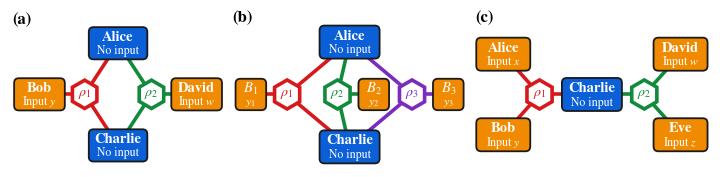

In [35]:
SRC = [RED, GREEN, PURPLE]

def node(ax, xy, label, sub, color, w, h):
    x, y = xy
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
                                fc=color, ec=DARK, lw=1.3, zorder=3))
    ax.text(x, y + 0.15, label, ha='center', va='center', color='white', fontsize=10.5, fontweight='bold', zorder=4)
    ax.text(x, y - 0.2, sub, ha='center', va='center', color='white', fontsize=8.5, zorder=4)

def source(ax, xy, label, color, targets):
    x, y = xy
    for t in targets:
        ax.plot([x, t[0]], [y, t[1]], color=color, lw=2.6, zorder=1, solid_capstyle='round')
    ax.add_patch(RegularPolygon((x, y), 6, radius=0.36, fc='white', ec=color, lw=2.6, zorder=3))
    ax.text(x, y, label, ha='center', va='center', fontsize=10, color=color, fontweight='bold', zorder=4)

fig, axs = plt.subplots(1, 3, figsize=(7.05, 2.2), gridspec_kw=dict(width_ratios=[1, 1.1, 1.1]))
for ax in axs:
    ax.set_aspect('equal'); ax.axis('off')
HW, HH = 1.45, 0.78
ax = axs[0]; A, C = (0, 1.3), (0, -1.3); B, D = (-2.0, 0), (2.0, 0)
source(ax, (-0.85, 0), r'$\rho_1$', SRC[0], [A, C, B]); source(ax, (0.85, 0), r'$\rho_2$', SRC[1], [A, C, D])
node(ax, A, 'Alice', 'No input', BLUE, HW, HH); node(ax, C, 'Charlie', 'No input', BLUE, HW, HH)
node(ax, B, 'Bob', r'Input $y$', ORANGE, 1.25, HH); node(ax, D, 'David', r'Input $w$', ORANGE, 1.25, HH)
ax.set_xlim(-2.75, 2.75); ax.set_ylim(-1.8, 2.1); ax.text(-2.7, 1.8, '(a)', fontsize=12, fontweight='bold')
ax = axs[1]; A, C = (0, 1.3), (0, -1.3)
S3 = [(-1.55, 0), (-0.3, 0), (1.55, 0)]; E3 = [(-2.45, 0), (0.6, 0), (2.45, 0)]
for k in (0, 2, 1):
    source(ax, S3[k], r'$\rho_%d$' % (k + 1), SRC[k], [A, C, E3[k]])
node(ax, A, 'Alice', 'No input', BLUE, HW, HH); node(ax, C, 'Charlie', 'No input', BLUE, HW, HH)
for k, p in enumerate(E3):
    node(ax, p, r'$B_%d$' % (k + 1), r'$y_%d$' % (k + 1), ORANGE, 0.72, 0.74)
ax.set_xlim(-2.95, 2.95); ax.set_ylim(-1.8, 2.1); ax.text(-2.9, 1.8, '(b)', fontsize=12, fontweight='bold')
ax = axs[2]; Cc = (0, 0); A, B, D, E = (-2.2, 1.0), (-2.2, -1.0), (2.2, 1.0), (2.2, -1.0)
source(ax, (-1.3, 0), r'$\rho_1$', SRC[0], [A, B, Cc]); source(ax, (1.3, 0), r'$\rho_2$', SRC[1], [D, E, Cc])
node(ax, Cc, 'Charlie', 'No input', BLUE, HW, HH)
node(ax, A, 'Alice', r'Input $x$', ORANGE, 1.3, HH); node(ax, B, 'Bob', r'Input $y$', ORANGE, 1.3, HH)
node(ax, D, 'David', r'Input $w$', ORANGE, 1.3, HH); node(ax, E, 'Eve', r'Input $z$', ORANGE, 1.3, HH)
ax.set_xlim(-2.95, 2.95); ax.set_ylim(-1.8, 2.1); ax.text(-2.9, 1.8, '(c)', fontsize=12, fontweight='bold')
fig.subplots_adjust(left=0.003, right=0.997, top=0.999, bottom=0.001, wspace=0.02)
fig.savefig('fig1_networks.pdf'); plt.show()

### Fig. 2: generalized GHZ states and critical visibilities

(a) Values in units of the local bound. Blue: closed network $\sqrt{1+\sin^22\alpha}$. Green dashed: $\mathcal S/4$. Red: $\mathcal N_o$. Orange dotted: $\mathcal M/2$. (b) Visibility ranges in which noisy GHZ (solid bars) and noisy $W$ (hatched bars) states violate each inequality. The $W$ bar of the closed network uses the numerical value $\mathcal N_c^{\rm prod}$, so its threshold is an upper bound ($\le$), and the black tick marks the threshold with Bell-state measurements. All $W$ thresholds are taken from the values computed above.

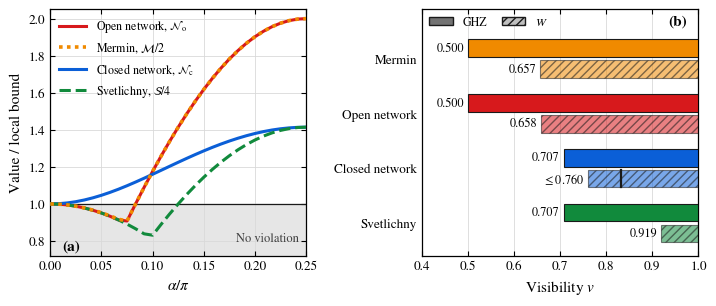

In [37]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.05, 2.95), gridspec_kw=dict(width_ratios=[1, 1.08]))
x = GG['al']/np.pi
ax.grid(True, zorder=0); ax.axhspan(0.72, 1, color='0.9', zorder=0)
ax.plot(x, GG['NO'], color=RED, label=r'Open network, $\mathcal{N}_{\rm o}$', zorder=3)
ax.plot(x, GG['M'], color=ORANGE, ls=(0, (1, 1.2)), lw=2.6, label=r'Mermin, $\mathcal{M}/2$', zorder=4)
ax.plot(x, np.sqrt(1 + np.sin(2*GG['al'])**2), color=BLUE, label=r'Closed network, $\mathcal{N}_{\rm c}$', zorder=3)
ax.plot(x, GG['SV'], color=GREEN, ls='--', label=r'Svetlichny, $\mathcal{S}/4$', zorder=3)
ax.axhline(1, color=DARK, lw=0.9)
ax.set_xlim(0, 0.25); ax.set_ylim(0.72, 2.05); ax.set_xlabel(r'$\alpha/\pi$'); ax.set_ylabel('Value / local bound')
ax.legend(loc='upper left', frameon=False, handlelength=2.3, borderaxespad=0.3)
ax.text(0.243, 0.80, 'No violation', ha='right', fontsize=9, color='0.25'); ax.text(0.012, 0.75, '(a)', fontsize=11, fontweight='bold')

bars = [('Mermin', ORANGE, 0.5, 1/MW), ('Open network', RED, 0.5, 1/NoW),
        ('Closed network', BLUE, 1/r2, 1/NcprodW), ('Svetlichny', GREEN, 1/r2, 1/SvW)]
yy = np.arange(len(bars))[::-1]
bx.grid(True, axis='x', zorder=0)
for (name, c, vg, vw), y in zip(bars, yy):
    bx.barh(y + 0.19, 1 - vg, left=vg, height=0.32, color=c, ec=DARK, lw=0.8, zorder=3)
    bx.barh(y - 0.19, 1 - vw, left=vw, height=0.32, color=c, ec=DARK, lw=0.8, hatch='////', alpha=0.55, zorder=3)
    bx.text(vg - 0.008, y + 0.19, '%.3f' % vg, ha='right', va='center', fontsize=8.8)
    bx.text(vw - 0.008, y - 0.19, (r'$\leq$%.3f' if name.startswith('Closed') else '%.3f') % vw, ha='right', va='center', fontsize=8.8)
bx.plot([1/NcW]*2, [yy[2] - 0.35, yy[2] - 0.03], color=DARK, lw=1.6, zorder=4)
bx.set_yticks(yy); bx.set_yticklabels([b[0] for b in bars]); bx.set_xlim(0.4, 1.0); bx.set_ylim(-0.6, 3.9)
bx.set_xlabel(r'Visibility $v$'); bx.tick_params(axis='y', length=0)
bx.legend(handles=[Patch(fc='0.45', ec=DARK, label='GHZ'), Patch(fc='0.75', ec=DARK, hatch='////', label=r'$W$')],
          loc='upper left', frameon=False, ncol=2, borderaxespad=0.2, columnspacing=1.2)
bx.text(0.975, 3.62, '(b)', fontsize=11, fontweight='bold', ha='right')
fig.tight_layout(pad=0.3, w_pad=1.2); fig.savefig('fig2_hierarchy.pdf'); plt.show()

### Fig. 3: random states

(a) $\mathcal N_c$ against $\mathcal S/4$: blue circles are pure states, orange squares rank-two states. All points lie above the black diagonal (Theorem 2). (b) $\mathcal N_o$ against $\mathcal M/2$: red circles are pure states, green squares rank-two states. All points lie on or below the diagonal (Theorem 3).

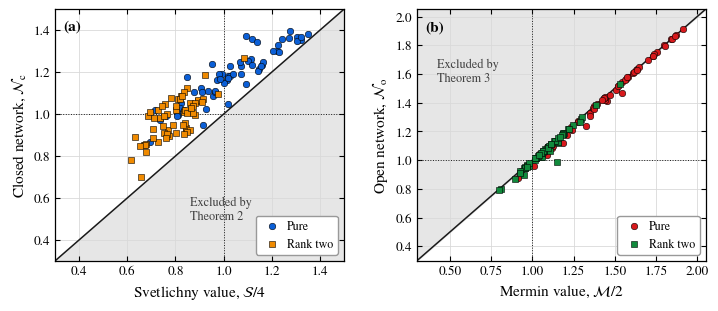

In [39]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.05, 3.0))
k = len(R)//2
for a in (ax, bx):
    a.grid(True, zorder=0)
ax.fill_between([0.3, 1.5], [0.3, 1.5], 0.3, color='0.9', zorder=1); ax.plot([0.3, 1.5], [0.3, 1.5], color=DARK, lw=1.1, zorder=2)
ax.scatter(R[:k, 1], R[:k, 0], s=22, color=BLUE, ec='k', lw=0.4, label='Pure', zorder=3)
ax.scatter(R[k:, 1], R[k:, 0], s=24, color=ORANGE, ec='k', lw=0.4, marker='s', label='Rank two', zorder=3)
ax.axhline(1, color=DARK, lw=0.7, ls=':'); ax.axvline(1, color=DARK, lw=0.7, ls=':')
ax.set_xlim(0.3, 1.5); ax.set_ylim(0.3, 1.5); ax.set_xlabel(r'Svetlichny value, $\mathcal{S}/4$'); ax.set_ylabel(r'Closed network, $\mathcal{N}_{\rm c}$')
ax.legend(loc='lower right', frameon=True, framealpha=1, edgecolor='0.6', handletextpad=0.2)
ax.text(0.335, 1.40, '(a)', fontsize=11, fontweight='bold'); ax.text(0.86, 0.50, 'Excluded by\nTheorem 2', fontsize=8.8, color='0.25')
bx.fill_between([0.3, 2.05], [0.3, 2.05], 2.05, color='0.9', zorder=1); bx.plot([0.3, 2.05], [0.3, 2.05], color=DARK, lw=1.1, zorder=2)
bx.scatter(R[:k, 3], R[:k, 2], s=22, color=RED, ec='k', lw=0.4, label='Pure', zorder=3)
bx.scatter(R[k:, 3], R[k:, 2], s=24, color=GREEN, ec='k', lw=0.4, marker='s', label='Rank two', zorder=3)
bx.axhline(1, color=DARK, lw=0.7, ls=':'); bx.axvline(1, color=DARK, lw=0.7, ls=':')
bx.set_xlim(0.3, 2.05); bx.set_ylim(0.3, 2.05); bx.set_xlabel(r'Mermin value, $\mathcal{M}/2$'); bx.set_ylabel(r'Open network, $\mathcal{N}_{\rm o}$')
bx.legend(loc='lower right', frameon=True, framealpha=1, edgecolor='0.6', handletextpad=0.2)
bx.text(0.35, 1.90, '(b)', fontsize=11, fontweight='bold'); bx.text(0.42, 1.55, 'Excluded by\nTheorem 3', fontsize=8.8, color='0.25')
fig.tight_layout(pad=0.3, w_pad=1.4); fig.savefig('fig3_random.pdf'); plt.show()

## Part 6. The swapped state at the end nodes (Sec. IV and App. F)

### 6.1 Swapping through two central nodes

We take $n$ copies of a three-qubit state (qubit order $A\,B\,C$ within each source), let both central nodes project onto the $n$-qubit GHZ basis $(|\boldsymbol k\rangle\pm|\bar{\boldsymbol k}\rangle)/\sqrt2$ (for $n=2$ this is the Bell basis), and return, for every pair of outcomes, the probability and the normalized state of the end nodes.

The basis is ordered as $(\boldsymbol k,+),(\boldsymbol k,-)$ for $\boldsymbol k=0,1,\dots$; for $n=2$ the outcomes $0,1,2,3$ are $\Phi^+,\Phi^-,\Psi^+,\Psi^-$. Two outcomes have matching $\sigma_3$ parities when their index divided by two (integer division) agrees.

In [41]:
def ghz_basis(n):
    d = 2**n; out = []
    for k in range(d//2):
        for s in (1, -1):
            v = np.zeros(d); v[k] = 1/np.sqrt(2); v[d - 1 - k] = s/np.sqrt(2); out.append(v)
    return np.array(out)

def swap(rho, n, only=None):
    # Returns {(a, c): (probability, normalized state of the n end nodes)}.
    Rt = rho.reshape([2]*6)
    big = Rt
    for _ in range(n - 1):
        big = np.tensordot(big, Rt, axes=0)
    ket = [6*i + j for j in range(3) for i in range(n)]           # all A, then all B, then all C (kets)
    bra = [6*i + 3 + j for j in range(3) for i in range(n)]
    big = big.transpose(ket + bra).reshape([2**n]*6)
    Gb = ghz_basis(n); out = {}
    for a in range(2**n):
        for c in range(2**n):
            if only is not None and (a, c) not in only:
                continue
            s = np.einsum('i,l,ibljdm,j,m->bd', Gb[a], Gb[c], big, Gb[a], Gb[c], optimize=True)
            p = np.real(np.trace(s)); out[(a, c)] = (p, s/p if p > 1e-14 else None)
    return out

def chsh_max(s):
    # Horodecki formula: 2 sqrt(m1 + m2), m1, m2 the two largest eigenvalues of t^T t.
    t = np.array([[np.real(np.trace(s @ kron(PAULI[i], PAULI[j]))) for j in (1, 2, 3)] for i in (1, 2, 3)])
    e = np.sort(np.linalg.eigvalsh(t.T @ t)); return 2*np.sqrt(e[-1] + e[-2])

def concurrence(s):
    yy = kron(Y, Y)
    e = np.sqrt(np.abs(np.sort(np.real(np.linalg.eigvals(s @ yy @ s.conj() @ yy)))[::-1]))
    return max(0.0, e[0] - e[1] - e[2] - e[3])

### 6.2 Proposition 2 for pure GHZ sources

Every outcome that occurs has $c_z=a_z$ and leaves Bob and David in a Bell state (purity $1$, CHSH value $2\sqrt2$). Conditioned only on Alice's outcome (averaging over Charlie's), the state is separable (concurrence $0$).

In [43]:
o = swap(GHZ, 2)
for (a, c), (p, s) in o.items():
    if p > 1e-12:
        print("Outcomes (a, c) = (%d, %d):  probability %.4f,  CHSH %.4f,  purity %.3f" % (a, c, p, chsh_max(s), np.real(np.trace(s @ s))))
for a in range(4):
    s = sum(o[(a, c)][0]*o[(a, c)][1] for c in range(4) if o[(a, c)][1] is not None); s /= np.trace(s)
    print("Only Alice's outcome a = %d:  concurrence %.4f" % (a, concurrence(s)))

Outcomes (a, c) = (0, 0):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (0, 1):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (1, 0):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (1, 1):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (2, 2):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (2, 3):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (3, 2):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Outcomes (a, c) = (3, 3):  probability 0.1250,  CHSH 2.8284,  purity 1.000
Only Alice's outcome a = 0:  concurrence 0.0000
Only Alice's outcome a = 1:  concurrence 0.0000
Only Alice's outcome a = 2:  concurrence 0.0000
Only Alice's outcome a = 3:  concurrence 0.0000


### 6.3 Noisy GHZ sources, Eq. (17)

The herald $c_z=a_z$ has probability $(1+v^2)/2$ and leaves a Werner state of visibility $w=2v^2/(1+v^2)$, which we read off from the fidelity $F$ with $\Phi^+$ through $w=(4F-1)/3$. After the complementary event Bob and David are maximally mixed. The thresholds are $v>1/\sqrt5$ (entangled) and $v>(2\sqrt2-1)^{-1/2}$ (CHSH), compared with $v>1/\sqrt2$ for the network.

In [45]:
phi = dm(ghz(2))
for v in [0.5, 0.7071, 0.7395, 0.8, 0.9]:
    o = swap(noisy(GHZ, v), 2)
    pm = sum(p for (a, c), (p, s) in o.items() if a//2 == c//2)
    p, s = o[(0, 0)]
    w = (4*np.real(np.trace(s @ phi)) - 1)/3
    print("v = %.4f:  P(herald) = %.4f [(1+v^2)/2 = %.4f],  w = %.4f [2v^2/(1+v^2) = %.4f],  CHSH/2 = %.4f,  "
          "mismatch state = 1/4: %s" % (v, pm, (1 + v*v)/2, w, 2*v*v/(1 + v*v), chsh_max(s)/2,
                                         np.allclose(o[(0, 2)][1], np.eye(4)/4)))
print("Thresholds: entangled v > %.4f, CHSH v > %.4f, network v > %.4f, bipartite sources CHSH v > %.4f"
      % (1/np.sqrt(5), 1/np.sqrt(2*np.sqrt(2) - 1), 1/np.sqrt(2), 2**-0.25))

v = 0.5000:  P(herald) = 0.6250 [(1+v^2)/2 = 0.6250],  w = 0.4000 [2v^2/(1+v^2) = 0.4000],  CHSH/2 = 0.5657,  mismatch state = 1/4: True
v = 0.7071:  P(herald) = 0.7500 [(1+v^2)/2 = 0.7500],  w = 0.6667 [2v^2/(1+v^2) = 0.6667],  CHSH/2 = 0.9428,  mismatch state = 1/4: True
v = 0.7395:  P(herald) = 0.7734 [(1+v^2)/2 = 0.7734],  w = 0.7071 [2v^2/(1+v^2) = 0.7071],  CHSH/2 = 0.9999,  mismatch state = 1/4: True
v = 0.8000:  P(herald) = 0.8200 [(1+v^2)/2 = 0.8200],  w = 0.7805 [2v^2/(1+v^2) = 0.7805],  CHSH/2 = 1.1038,  mismatch state = 1/4: True
v = 0.9000:  P(herald) = 0.9050 [(1+v^2)/2 = 0.9050],  w = 0.8950 [2v^2/(1+v^2) = 0.8950],  CHSH/2 = 1.2658,  mismatch state = 1/4: True
Thresholds: entangled v > 0.4472, CHSH v > 0.7395, network v > 0.7071, bipartite sources CHSH v > 0.8409


### 6.4 $W$ sources

Bell state with probability $4/9$, concurrence $4/5$ with probability $5/18$, separable otherwise, average concurrence $2/3$. With only Alice's outcome some entanglement is already swapped.

In [47]:
o = swap(W, 2); avg = 0.0; classes = {}
for (a, c), (p, s) in o.items():
    if p > 1e-12:
        C = float(round(concurrence(s), 4)); classes[C] = classes.get(C, 0.0) + float(p); avg += p*C
print("Concurrence: probability =", {k: round(v, 4) for k, v in sorted(classes.items())}, "   average concurrence:", round(float(avg), 4))
for a in range(4):
    s = sum(o[(a, c)][0]*o[(a, c)][1] for c in range(4) if o[(a, c)][1] is not None); pa = np.real(np.trace(s)); s /= pa
    print("Only Alice's outcome a = %d (probability %.3f):  concurrence %.4f" % (a, pa, concurrence(s)))

Concurrence: probability = {0.0: 0.2778, 0.8: 0.2778, 1.0: 0.4444}    average concurrence: 0.6667
Only Alice's outcome a = 0 (probability 0.278):  concurrence 0.0000
Only Alice's outcome a = 1 (probability 0.278):  concurrence 0.0000
Only Alice's outcome a = 2 (probability 0.222):  concurrence 0.5000
Only Alice's outcome a = 3 (probability 0.222):  concurrence 0.5000


### Fig. 4: network value and CHSH value of the swapped state

Blue: $\mathcal N_c=\sqrt2v$. Red dashed: half the CHSH value of the heralded state, $\sqrt2\,w$. Green dotted: the same for two bipartite Werner sources, $\sqrt2v^2$. In the shaded window the network inequality is violated while the heralded state does not violate CHSH.

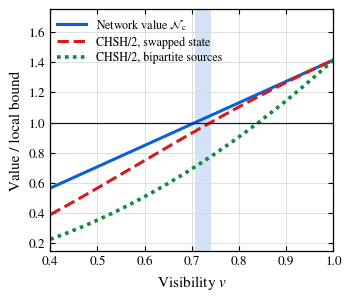

In [49]:
v = np.linspace(0.4, 1, 400)
fig, ax = plt.subplots(figsize=(3.4, 2.9))
ax.grid(True, zorder=0)
ax.axvspan(1/r2, np.sqrt(1/(2*r2 - 1)), color=BLUE, alpha=0.18, lw=0)
ax.plot(v, r2*v, color=BLUE, label=r'Network value $\mathcal{N}_{\rm c}$')
ax.plot(v, r2*2*v**2/(1 + v**2), color=RED, ls='--', label='CHSH/2, swapped state')
ax.plot(v, r2*v**2, color=GREEN, ls=(0, (1, 1.2)), lw=2.6, label='CHSH/2, bipartite sources')
ax.axhline(1, color=DARK, lw=0.9)
ax.set_xlim(0.4, 1); ax.set_ylim(0.15, 1.75); ax.set_xlabel(r'Visibility $v$'); ax.set_ylabel('Value / local bound')
ax.legend(loc='upper left', frameon=False, handlelength=2.4, borderaxespad=0.2, labelspacing=0.3)
fig.tight_layout(pad=0.3); fig.savefig('fig4_swapping.pdf'); plt.show()

## Part 7. The open network (Sec. V)

### 7.1 Two GHZ sources reach the algebraic maximum $2$

End nodes measure $\sigma_1$ (setting 0) and $\sigma_2$ (setting 1). The central node performs a Bell-state measurement and uses its $\sigma_1\otimes\sigma_1$ and $\sigma_2\otimes\sigma_2$ parities as $g_0,g_1$. We evaluate $I_{\rm o}=\langle g_0U_0V_0\rangle$ and $J_{\rm o}=\langle g_1U_1V_1\rangle$ directly on the six-qubit state (qubit order $A\,B\,C_1\,C_2\,D\,E$).

In [51]:
psi2 = kron(ghz(), ghz())                              # (A B C1)(C2 D E): C1 C2 sit in the middle
U0 = (kron(X, X) - kron(Y, Y))/2; U1 = (kron(X, Y) + kron(Y, X))/2
ev = lambda U, V, s: np.real(psi2.conj() @ (np.kron(np.kron(U, kron(s, s)), V) @ psi2))
Io, Jo = ev(U0, U0, X), ev(U1, U1, Y)
print("I_o = %.3f,  J_o = %.3f,  sqrt|I_o| + sqrt|J_o| = %.4f" % (Io, Jo, np.sqrt(abs(Io)) + np.sqrt(abs(Jo))))

I_o = 1.000,  J_o = 1.000,  sqrt|I_o| + sqrt|J_o| = 2.0000


### 7.2 Theorem 3 and the biseparable examples

The random-state check of Theorem 3 was done in Part 5.2 and the generalized GHZ comparison in Part 5.3. Here we check the converse examples: $|\Phi^+\rangle_{AB}|0\rangle_C$ with the unentangled particle at the central node gives $\mathcal M/2=\sqrt2$ but $\mathcal N_o=1$, while $|0\rangle_A|\Phi^+\rangle_{BC}$ (unentangled particle at an end node) gives $\mathcal N_o=\sqrt2$.

In [53]:
bisep_A = dm(np.kron(z0, bell))                       # |0>_A x Phi+_BC
print("Phi+_AB x |0>_C:  N_o = %.4f,  M/2 = %.4f" % (N_open(bisep_AB, 30), mermin_max(bisep_AB, 30)/2))
print("|0>_A x Phi+_BC:  N_o = %.4f" % N_open(bisep_A, 30))

Phi+_AB x |0>_C:  N_o = 1.0000,  M/2 = 1.4142
|0>_A x Phi+_BC:  N_o = 1.4142


## Part 8. Many sources and the parity effect (Sec. VI and App. E)

### 8.1 Theorem 4: numerical test of the upper bounds

**Closed network.** By Lemma 1 we can test the bound with a single central node. We take a star with $n$ Bell pairs $|\Phi^+\rangle$ and let the central node measure its $n$ qubits in an arbitrary orthonormal basis (columns of $U=\exp(iH)$, $H$ with $4^n$ real parameters). End node $i$ has the angle $\theta_i$ and perpendicular directions $\boldsymbol n_i,\boldsymbol n_i'$. For $\Phi^+$ the conditional expectation of $P$ given outcome $k$ is $\langle k|P^T|k\rangle$ up to the probability, so $\bar p=2^{-n}\sum_k|\langle k|P^T|k\rangle|$. Theorem 4 predicts $\sqrt2$ for even $n$ and $2^{1/2-1/(2n)}$ for odd $n$.

**Open network.** Three GHZ sources, a central node measuring its three qubits in an arbitrary basis, and Mermin kernels at the end nodes. Theorem 4 predicts the tight bound $2^{5/6}\approx1.7818$. We evaluate the optimal strategy of App. E, which reaches the bound, and a random multistart search, which can only find lower values (local optimization often stops at $2^{2/3}$).

In [55]:
def star_value(x, n):
    d = 2**n
    U = unitary(x[:d*d], d); off = d*d
    P = Q = np.ones((1, 1)); cs = sn = 1.0
    for i in range(n):
        a = x[off + 5*i: off + 5*i + 5]
        nb = unit(a[0], a[1]); e = np.cross(nb, unit(a[2], a[3])); e /= np.linalg.norm(e) + 1e-15
        P = np.kron(P, spin(nb)); Q = np.kron(Q, spin(e))
        cs *= abs(np.cos(a[4])); sn *= abs(np.sin(a[4]))
    p = np.abs(np.real(np.einsum('ik,ij,jk->k', U.conj(), P.T, U))).mean()
    q = np.abs(np.real(np.einsum('ik,ij,jk->k', U.conj(), Q.T, U))).mean()
    return (cs*p)**(1/n) + (sn*q)**(1/n)

t0 = time.time(); rng = np.random.default_rng(11)
for n in [1, 2, 3, 4]:
    d = 2**n; best = 0.0
    for _ in range(12 if n < 4 else 5):
        x0 = np.r_[rng.normal(size=d*d), rng.uniform(0, 3, 5*n)]
        r = minimize(lambda x: -star_value(x, n), x0, method='L-BFGS-B', options=dict(maxiter=600))
        best = max(best, -r.fun)
    bound = np.sqrt(2) if n % 2 == 0 else 2**(0.5 - 0.5/n)
    print("Closed, n = %d:  numerical maximum %.5f,  Theorem 4: %.5f" % (n, best, bound))

T_G = corr_tensor(GHZ)
def kernel_operator(T, y):
    # Reduced operator of the central qubit for the kernels U0 and U1 of one source:
    # K0 = Tr_AB[rho (U0 x 1)] = (1/2) sum_m Tr[rho U0 x sigma_m] sigma_m, with m = 0..3, and the same for U1.
    a0, a1, b0, b1 = [unit(y[2*j], y[2*j + 1]) for j in range(4)]
    G = T[1:, 1:, :]                                   # end-node indices 1..3, central index 0..3
    w0 = 0.5*(np.einsum('ikm,i,k->m', G, a0, b0) - np.einsum('ikm,i,k->m', G, a1, b1))
    w1 = 0.5*(np.einsum('ikm,i,k->m', G, a0, b1) + np.einsum('ikm,i,k->m', G, a1, b0))
    return sum(w0[m]*PAULI[m] for m in range(4))/2, sum(w1[m]*PAULI[m] for m in range(4))/2

def open3_value(U, a):
    Ks = [kernel_operator(T_G, a[8*i:8*i + 8]) for i in range(3)]
    Pm, Qm = kron(*[k[0] for k in Ks]), kron(*[k[1] for k in Ks])
    # <k|Pm|k> is the weight of central-node outcome k in <g0 U0 U0 U0>; the best signs give the sum of moduli.
    p = np.abs(np.real(np.einsum('ik,ij,jk->k', U.conj(), Pm, U))).sum()
    q = np.abs(np.real(np.einsum('ik,ij,jk->k', U.conj(), Qm, U))).sum()
    return p**(1/3) + q**(1/3)

# (i) The optimal strategy of App. E: Bell-state measurement on the first two central qubits, the third measured
#     along (x + y)/sqrt2, and all end nodes measuring sigma_1 (setting 0) and sigma_2 (setting 1).
bell_basis = np.array([[1, 0, 0, 1], [1, 0, 0, -1], [0, 1, 1, 0], [0, 1, -1, 0]]).T/np.sqrt(2)
_, Vxy = np.linalg.eigh((X + Y)/r2 if 'r2' in dir() else (X + Y)/np.sqrt(2))
U_opt = np.kron(bell_basis, Vxy)
a_opt = np.tile([np.pi/2, 0, np.pi/2, np.pi/2, np.pi/2, 0, np.pi/2, np.pi/2], 3)
print("Open,   n = 3:  optimal strategy of App. E gives %.5f,  Theorem 4: %.5f" % (open3_value(U_opt, a_opt), 2**(5/6)))

# (ii) A numerical search over all central-node bases and end-node settings never exceeds the bound.
best = max(-minimize(lambda x: -open3_value(unitary(x[:64], 8), x[64:]),
                     np.r_[rng.normal(size=64), rng.uniform(0, 6, 24)],
                     method='L-BFGS-B', options=dict(maxiter=800)).fun for _ in range(15))
print("Open,   n = 3:  best value of a random multistart search %.5f  (must not exceed %.5f)" % (best, 2**(5/6)))
print("(%.0f s)" % (time.time() - t0))

Closed, n = 1:  numerical maximum 1.00000,  Theorem 4: 1.00000
Closed, n = 2:  numerical maximum 1.41421,  Theorem 4: 1.41421
Closed, n = 3:  numerical maximum 1.25992,  Theorem 4: 1.25992
Closed, n = 4:  numerical maximum 1.41226,  Theorem 4: 1.41421
Open,   n = 3:  optimal strategy of App. E gives 1.78180,  Theorem 4: 1.78180
Open,   n = 3:  best value of a random multistart search 1.78180  (must not exceed 1.78180)
(71 s)


Closed, n = 3:  numerical maximum 1.25992,  Theorem 4: 1.25992


Closed, n = 4:  numerical maximum 1.41228,  Theorem 4: 1.41421
Open,   n = 3:  optimal strategy of App. E gives 1.78180,  Theorem 4: 1.78180


Open,   n = 3:  best value of a random multistart search 1.78180  (must not exceed 1.78180)
(56 s)


### 8.2 The optimal strategy for three sources in the closed network

Both central nodes measure in the three-qubit GHZ basis, which fixes $\sigma_1\sigma_1\sigma_1$ and $\sigma_2\sigma_2\sigma_1$. We take $f_0=(\sigma_1\sigma_1\sigma_1)_A(\sigma_1\sigma_1\sigma_1)_C$ and $f_1=(\sigma_2\sigma_2\sigma_1)_A(\sigma_1\sigma_1\sigma_1)_C$, with end-node settings $(\sigma_1\pm\sigma_2)/\sqrt2$ for $B_1,B_2$ and $\sigma_1,\sigma_2$ for $B_3$, and evaluate $I$ and $J$ on the nine-qubit state (order $A_1B_1C_1A_2B_2C_2A_3B_3C_3$). The paper gives $I=J=1/4$ and the value $2^{1/3}$.

In [57]:
psi3 = kron(ghz(), ghz(), ghz())
ev9 = lambda ops: np.real(psi3.conj() @ (kron(*ops) @ psi3))
Bp = [(X + Y)/r2, (X - Y)/r2]; B3 = [X, Y]
I3 = J3 = 0.0
for y in itertools.product(range(2), repeat=3):
    b = [Bp[y[0]], Bp[y[1]], B3[y[2]]]
    I3 += ev9([X, b[0], X, X, b[1], X, X, b[2], X])/8
    J3 += (-1)**sum(y)*ev9([Y, b[0], X, Y, b[1], X, X, b[2], X])/8
print("I = %.4f,  J = %.4f,  |I|^(1/3) + |J|^(1/3) = %.5f,  2^(1/3) = %.5f"
      % (I3, J3, abs(I3)**(1/3) + abs(J3)**(1/3), 2**(1/3)))

I = 0.2500,  J = 0.2500,  |I|^(1/3) + |J|^(1/3) = 1.25992,  2^(1/3) = 1.25992


### 8.3 Tripartite swapping with noisy GHZ sources

The central nodes find matching GHZ-basis outcomes with probability $(1+3v^2)/4$. The heralded state is diagonal in the GHZ basis with coherence $\langle000|\rho|111\rangle=2v^3/(1+3v^2)$, and its Mermin and Svetlichny values are $8$ and $8\sqrt2$ times this coherence, i.e. $16v^3/(1+3v^2)$ and $16\sqrt2v^3/(1+3v^2)$. We check the coherence and the two values numerically, and then compute the thresholds $0.661$ (Mermin), $0.804$ (Svetlichny) and $2^{-1/3}\approx0.794$ (network).

In [59]:
t0 = time.time()
for v in [0.8, 1.0]:
    o = swap(noisy(GHZ, v), 3)
    pm = sum(p for (a, c), (p, s) in o.items() if a//2 == c//2)
    s = o[(0, 0)][1]
    coh = np.real(s[0, 7])
    print("v = %.1f:  P(herald) = %.4f [(1+3v^2)/4 = %.4f],  coherence = %.5f [2v^3/(1+3v^2) = %.5f],  "
          "M = %.4f [%.4f],  S = %.4f [%.4f]" % (v, pm, (1 + 3*v*v)/4, coh, 2*v**3/(1 + 3*v*v),
          mermin_max(s, 20), 16*v**3/(1 + 3*v*v), svetlichny_max(s, 20), 16*r2*v**3/(1 + 3*v*v)))
vM = brentq(lambda v: 16*v**3/(1 + 3*v*v) - 2, 0.3, 1)
vS = brentq(lambda v: 16*r2*v**3/(1 + 3*v*v) - 4, 0.3, 1)
print("Thresholds: Mermin v > %.4f,  Svetlichny v > %.4f,  network v > %.4f" % (vM, vS, 2**(-1/3)))
print("(%.0f s)" % (time.time() - t0))

v = 0.8:  P(herald) = 0.7300 [(1+3v^2)/4 = 0.7300],  coherence = 0.35068 [2v^3/(1+3v^2) = 0.35068],  M = 2.8055 [2.8055],  S = 3.9675 [3.9675]
v = 1.0:  P(herald) = 1.0000 [(1+3v^2)/4 = 1.0000],  coherence = 0.50000 [2v^3/(1+3v^2) = 0.50000],  M = 4.0000 [4.0000],  S = 5.6569 [5.6569]
Thresholds: Mermin v > 0.6610,  Svetlichny v > 0.8039,  network v > 0.7937
(1 s)


### Fig. 5: the parity effect

(a) Maximal quantum values from Theorem 4 for the closed network (blue) and the open network (red). Filled circles: odd $n$. Open squares: even $n$. The black line is the local bound. (b) Critical visibilities of noisy GHZ sources for the strategies that attain these maxima: $1/\sqrt2$ and $2^{-1/2+1/(2n)}$ (closed), $1/2$ and $2^{-1+1/(2n)}$ (open).

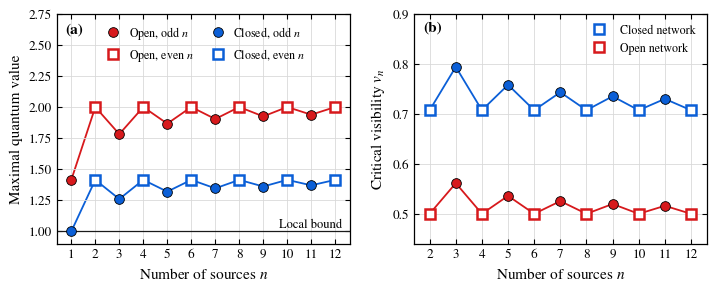

In [61]:
n = np.arange(1, 13); odd = n % 2 == 1
closed = np.where(odd, 2**(0.5 - 0.5/n), r2); opened = np.where(odd, 2**(1 - 0.5/n), 2.0)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.05, 2.8))
ax.grid(True, zorder=0); bx.grid(True, zorder=0)
ax.plot(n, opened, '-', color=RED, lw=1.3, zorder=1); ax.plot(n, closed, '-', color=BLUE, lw=1.3, zorder=1)
ax.plot(n[odd], opened[odd], 'o', color=RED, ms=7, mec='k', mew=0.6, label='Open, odd $n$', zorder=3)
ax.plot(n[~odd], opened[~odd], 's', color=RED, ms=7, mfc='white', mew=1.8, label='Open, even $n$', zorder=3)
ax.plot(n[odd], closed[odd], 'o', color=BLUE, ms=7, mec='k', mew=0.6, label='Closed, odd $n$', zorder=3)
ax.plot(n[~odd], closed[~odd], 's', color=BLUE, ms=7, mfc='white', mew=1.8, label='Closed, even $n$', zorder=3)
ax.axhline(1, color=DARK, lw=0.9); ax.text(12.3, 1.03, 'Local bound', ha='right', fontsize=9)
ax.set_xlim(0.4, 12.6); ax.set_ylim(0.9, 2.75); ax.set_xticks(n); ax.set_xlabel('Number of sources $n$'); ax.set_ylabel('Maximal quantum value')
ax.legend(loc='upper center', ncol=2, frameon=False, columnspacing=1.0, handletextpad=0.3)
ax.text(0.75, 2.6, '(a)', fontsize=11, fontweight='bold')
m = n >= 2
bx.plot(n[m], 1/closed[m], '-', color=BLUE, lw=1.3); bx.plot(n[m], 1/opened[m], '-', color=RED, lw=1.3)
bx.plot(n[m & odd], 1/closed[m & odd], 'o', color=BLUE, ms=7, mec='k', mew=0.6, zorder=3)
bx.plot(n[m & ~odd], 1/closed[m & ~odd], 's', color=BLUE, ms=7, mfc='white', mew=1.8, label='Closed network', zorder=3)
bx.plot(n[m & odd], 1/opened[m & odd], 'o', color=RED, ms=7, mec='k', mew=0.6, zorder=3)
bx.plot(n[m & ~odd], 1/opened[m & ~odd], 's', color=RED, ms=7, mfc='white', mew=1.8, label='Open network', zorder=3)
bx.set_xlim(1.4, 12.6); bx.set_ylim(0.44, 0.9); bx.set_xticks(n[m]); bx.set_xlabel('Number of sources $n$'); bx.set_ylabel(r'Critical visibility $v_n$')
bx.legend(loc='upper right', frameon=False); bx.text(1.75, 0.865, '(b)', fontsize=11, fontweight='bold')
fig.tight_layout(pad=0.3, w_pad=1.4); fig.savefig('fig5_parity.pdf'); plt.show()

## Summary

The notebook has reproduced every number of the paper: the local bounds, Proposition 1, the GHZ, generalized GHZ, $W$ and biseparable examples of Table III, the inequalities of Theorems 2 and 3 on random states, the swapping results of Proposition 2 with their noise thresholds, the open-network value $2$, the parity bounds of Theorem 4 with their optimal strategies, and the tripartite swapping thresholds. The five figures of the paper are saved as `fig1_networks.pdf` to `fig5_parity.pdf`.